<a href="https://colab.research.google.com/github/TuanSoCode/Imagine/blob/main/Auditdataamazon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import kagglehub,os,pandas as pd
path = kagglehub.dataset_download("rohiteng/amazon-sales-dataset")
print(os.listdir(path))
df=pd.read_csv(path + "/Amazon.csv")

Using Colab cache for faster access to the 'amazon-sales-dataset' dataset.
['Amazon.csv']


In [4]:
df = df[df['OrderStatus'].isin(['Delivered', 'Shipped'])]
print(f'Filtered DataFrame shape for Delivered & Shipped: {df.shape}')

Filtered DataFrame shape for Delivered & Shipped: (89820, 20)


In [5]:
df.head(10)

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
5,ORD0000006,2022-12-31,CUST042705,Karan Sharma,P00023,Cookware Set,Books,ReadMore,4,449.73,0.00,215.87,2.74,2017.53,UPI,Delivered,Los Angeles,CA,United States,SELL01494
6,ORD0000007,2024-09-20,CUST037667,Aarav Verma,P00030,Dress Shirt,Clothing,UrbanStyle,2,219.81,0.20,28.14,14.97,394.81,UPI,Delivered,Chicago,IL,Australia,SELL01676
8,ORD0000009,2024-06-26,CUST026965,Aman Kapoor,P00031,Kids Toy Car,Sports & Outdoors,Apex,4,146.09,0.00,46.75,7.03,638.14,Debit Card,Delivered,Washington,DC,United States,SELL01895
9,ORD0000010,2020-05-01,CUST029472,Aarav Reddy,P00001,Wireless Earbuds,Clothing,Apex,2,278.21,0.10,60.09,4.88,565.75,Credit Card,Delivered,Houston,TX,United States,SELL01584
10,ORD0000011,2021-04-11,CUST005346,Rohit Reddy,P00046,Car Charger,Books,HomeEase,1,141.42,0.05,6.72,9.70,150.77,Amazon Pay,Delivered,Jacksonville,FL,Australia,SELL01217
11,ORD0000012,2023-05-23,CUST046088,Karan Kumar,P00042,Projector Mini,Home & Kitchen,KiddoFun,5,346.56,0.05,131.69,13.38,1791.23,Credit Card,Shipped,Charlotte,NC,Australia,SELL01160


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89820 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        89820 non-null  object 
 1   OrderDate      89820 non-null  object 
 2   CustomerID     89820 non-null  object 
 3   CustomerName   89820 non-null  object 
 4   ProductID      89820 non-null  object 
 5   ProductName    89820 non-null  object 
 6   Category       89820 non-null  object 
 7   Brand          89820 non-null  object 
 8   Quantity       89820 non-null  int64  
 9   UnitPrice      89820 non-null  float64
 10  Discount       89820 non-null  float64
 11  Tax            89820 non-null  float64
 12  ShippingCost   89820 non-null  float64
 13  TotalAmount    89820 non-null  float64
 14  PaymentMethod  89820 non-null  object 
 15  OrderStatus    89820 non-null  object 
 16  City           89820 non-null  object 
 17  State          89820 non-null  object 
 18  Country    

In [7]:
df.describe()

,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount
count,89820.000000,89820.000000,89820.000000,89820.000000,89820.000000,89820.000000
mean,2.999544,302.917291,0.074252,68.429599,7.405839,918.017213
std,1.413359,171.852920,0.082600,74.172689,4.324897,724.658324
min,1.000000,5.000000,0.000000,0.000000,0.000000,4.270000
25%,2.000000,154.155000,0.000000,15.820000,3.680000,339.960000
50%,3.000000,303.290000,0.050000,45.160000,7.290000,713.920000
75%,4.000000,451.522500,0.100000,96.120000,11.150000,1350.737500
max,5.000000,599.990000,0.300000,538.460000,15.000000,3534.980000


In [8]:
df.nunique()

,0
OrderID,89820
OrderDate,1825
CustomerID,41738
CustomerName,200
ProductID,50
ProductName,50
Category,6
Brand,10
Quantity,5
UnitPrice,46352


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['PaymentMethod'].unique()

array(['Debit Card', 'Amazon Pay', 'Cash on Delivery', 'UPI',
       'Credit Card', 'Net Banking'], dtype=object)

In [11]:
import duckdb

In [12]:
import duckdb

query_city_only = """
SELECT
    City
FROM df
GROUP BY City
ORDER BY SUM(ShippingCost) / SUM(TotalAmount) DESC;
"""

cities_by_shipping_ratio = duckdb.sql(query_city_only).df()
display(cities_by_shipping_ratio)

,City
0,Houston
1,Washington
2,San Antonio
3,Jacksonville
4,New York
5,Austin
6,Columbus
7,Los Angeles
8,Phoenix
9,San Jose


In [13]:
import duckdb

query = """
SELECT
    City,
    SUM(ShippingCost) AS Total_Shipping_Cost,
    SUM(TotalAmount) AS Total_Revenue,
    ROUND(SUM(ShippingCost) / SUM(TotalAmount) * 100, 2) AS Shipping_Cost_Percentage
FROM df
GROUP BY City
ORDER BY Total_Shipping_Cost DESC;
"""

city_comparison = duckdb.sql(query).df()
display(city_comparison)

,City,Total_Shipping_Cost,Total_Revenue,Shipping_Cost_Percentage
0,Charlotte,34626.16,4298547.68,0.81
1,San Jose,34099.24,4229868.15,0.81
2,Austin,34000.22,4183848.37,0.81
3,Dallas,33738.96,4249189.86,0.79
4,Jacksonville,33580.87,4117885.37,0.82
5,Chicago,33544.30,4161551.37,0.81
6,Columbus,33535.31,4137317.84,0.81
7,New York,33445.09,4114209.97,0.81
8,Philadelphia,33383.96,4166124.62,0.80
9,Seattle,33338.24,4189455.72,0.80


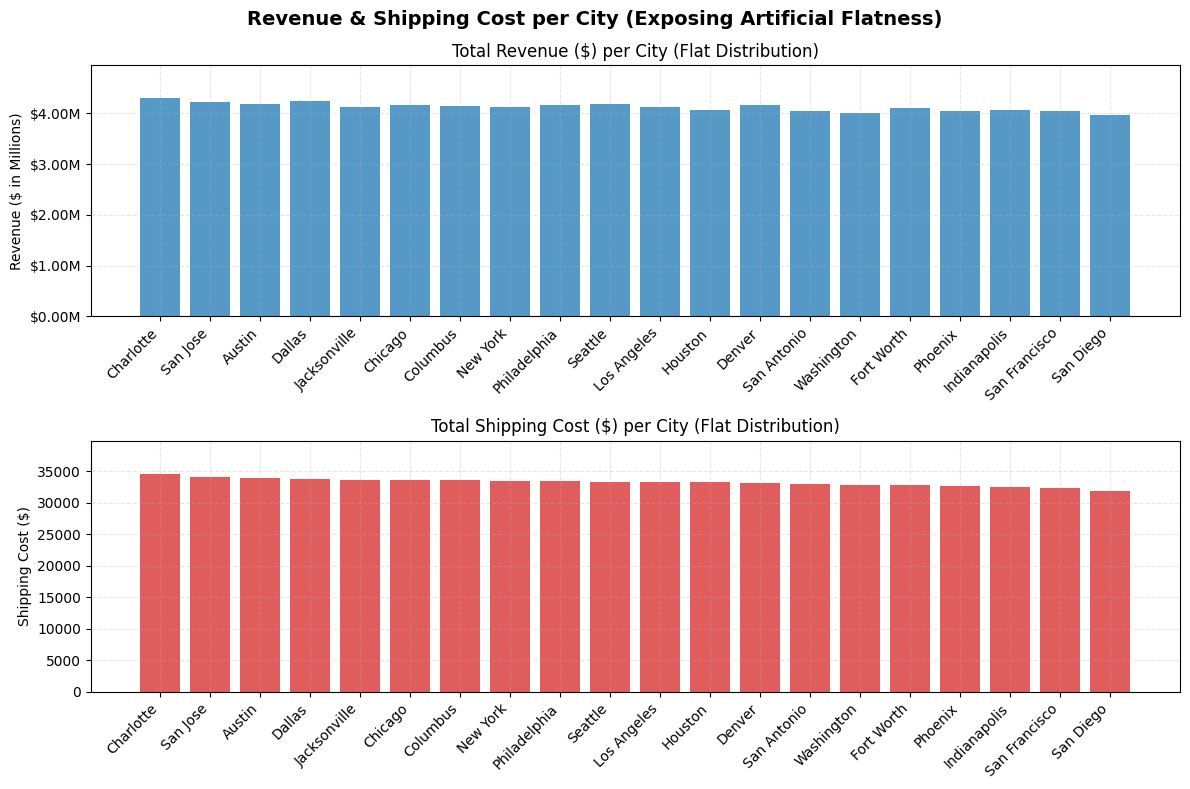

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

x_indices = np.arange(len(city_comparison['City']))
ax1.bar(x_indices, city_comparison['Total_Revenue'], color='#1f77b4', alpha=0.75)
ax1.set_title('Total Revenue ($) per City (Flat Distribution)')
ax1.set_ylabel('Revenue ($ in Millions)')
ax1.set_xticks(x_indices)
ax1.set_xticklabels(city_comparison['City'], rotation=45, ha='right')
ax1.set_ylim(0, city_comparison['Total_Revenue'].max() * 1.15)
ax1.get_yaxis().set_major_formatter(FuncFormatter(lambda x, p: f'${x*1e-6:.2f}M'))
ax1.grid(True, linestyle='--', alpha=0.3)

ax2.bar(x_indices, city_comparison['Total_Shipping_Cost'], color='#d62728', alpha=0.75)
ax2.set_title('Total Shipping Cost ($) per City (Flat Distribution)')
ax2.set_ylabel('Shipping Cost ($)')
ax2.set_xticks(x_indices)
ax2.set_xticklabels(city_comparison['City'], rotation=45, ha='right')
ax2.set_ylim(0, city_comparison['Total_Shipping_Cost'].max() * 1.15)
ax2.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Revenue & Shipping Cost per City (Exposing Artificial Flatness)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd
import numpy as np

def check_randomness(df, group_col, value_col, iterations=500):
    grouped = df.groupby(group_col)[value_col].sum()
    cv_actual = grouped.std() / grouped.mean()

    cv_random = []
    for i in range(iterations):
        shuffled = df[group_col].sample(frac=1, random_state=i).values
        temp_df = df.assign(**{f'{group_col}_shuffled': shuffled})
        grouped_rand = temp_df.groupby(f'{group_col}_shuffled')[value_col].sum()
        cv_random.append(grouped_rand.std() / grouped_rand.mean())

    p5, p50, p95 = np.percentile(cv_random, [5, 50, 95])

    print(f"Actual CV: {cv_actual:.4f}")
    print(f"Random CV (5%, 50%, 95%): [{p5:.4f}, {p50:.4f}, {p95:.4f}]")

    if cv_actual > p95:
        print("=> Result: This column HAS meaningful information (variance is significantly higher than random).")
    elif cv_actual < p5:
        print("=> Result: This column is FLATTER than random (strong indicator of synthetic/fake data).")
    else:
        print("=> Result: This column is STATISTICALLY RANDOM (no meaningful information).")

In [16]:
check_randomness(df, 'City', 'TotalAmount')

Actual CV: 0.0204
Random CV (5%, 50%, 95%): [0.0165, 0.0209, 0.0247]
=> Result: This column is STATISTICALLY RANDOM (no meaningful information).
